# Chapter 6 — Advanced Logistic Regression and Extensions

> Reproduction notebook for **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025).

## Chapter Summary

Regression is not only for numbers: **logistic regression** predicts *probabilities* of class membership, making it a workhorse for classification. The chapter extends it from binary to multiclass and multilabel problems, adds regularisation, and reviews evaluation metrics.

| Recipe | Key idea |
|---|---|
| Overview | Sigmoid of a linear combination → probability; trained with maximum likelihood |
| Multiclass | One-vs-Rest (one binary model per class) vs Multinomial / SoftMax (all classes at once) |
| Regularisation | L2 (Ridge) / L1 (Lasso) penalties; `C` = inverse of regularisation strength |
| Multilabel | Each sample can have several labels → one binary classifier per label |
| Evaluation | Accuracy, precision, recall, F1, ROC curve, AUC |

> **Version note.** The book targets scikit-learn 1.5, where `LogisticRegression(multi_class=...)` still exists. It was deprecated and later removed, and in recent versions a multiclass `LogisticRegression` is **always multinomial** with the default solver. To keep this notebook working on current versions, One-vs-Rest is built with `OneVsRestClassifier` — the result is the same strategy the book demonstrates.

## 1. Overview of logistic regression

**Theory.** Instead of predicting a number, logistic regression applies the **logistic (sigmoid) function** to a linear combination of the features:

$$P(Y=1\mid X)=\frac{1}{1+e^{-(\beta_0+\beta_1X_1+\dots+\beta_nX_n)}}$$

* Output is between 0 and 1 → interpreted as the probability of the positive class; a **threshold** (commonly 0.5) turns it into a class.
* Parameters are estimated by **maximum likelihood estimation (MLE)**.
* The decision boundary is linear in the **log-odds**. *Odds* = $P/(1-P)$ and *log-odds* = $\ln(\text{odds})$; the log-odds transformation maps probabilities (0–1) onto an unbounded linear scale.

Dataset: Breast Cancer Wisconsin (binary: malignant vs benign).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = load_breast_cancer()
X = data.data
y = data.target

# Convert to a DataFrame for easier manipulation (optional)
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    df[data.feature_names], df['target'], test_size=0.2, random_state=2024
)

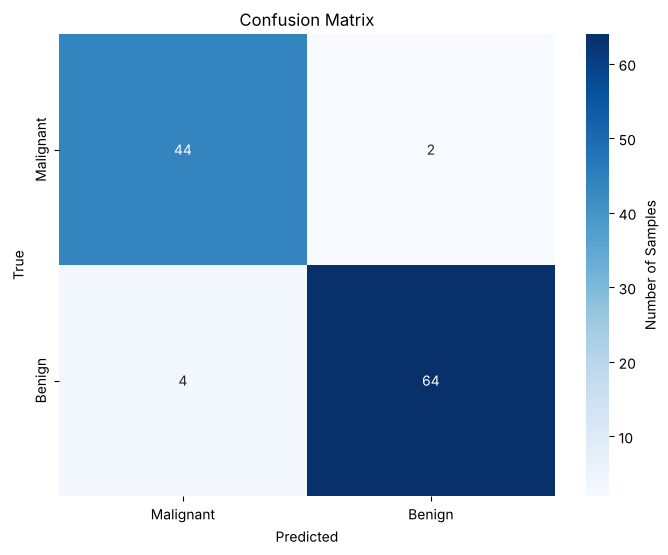

Accuracy: 0.95

Classification Report:


,precision,recall,f1-score,support
Malignant,0.917,0.957,0.936,46
Benign,0.970,0.941,0.955,68
accuracy,0.947,0.947,0.947,1
macro avg,0.943,0.949,0.946,114
weighted avg,0.948,0.947,0.948,114


In [2]:
model = LogisticRegression(max_iter=10000)  # increase max_iter if convergence issues occur
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

class_names = ['Malignant', 'Benign']
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix')
plt.show()

report_dict = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
styled_df = (report_df.style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

print(f'Accuracy: {accuracy:.2f}\n')
print("Classification Report:")
display(styled_df)

**Reading the result.** Even with defaults, accuracy is high. But for a medical problem accuracy is not the whole story — the book asks which other metric might be better. Answer: **recall for the malignant class** (missing a cancer — a false negative — is far more costly than a false alarm).

Other metrics: accuracy, confusion matrix (TP/TN/FP/FN), precision and recall, and ROC curves across thresholds.

## 2. Multiclass classification techniques

**Theory.** When there are more than two classes:

* **One-vs-Rest (OvR / one-vs-all):** train one binary classifier per class (that class = positive, all others = negative). At prediction time pick the class whose classifier is most confident. Solver `liblinear` is a common choice.
* **Multinomial (SoftMax) regression:** model the probabilities of all classes **simultaneously** with the SoftMax function and optimise all coefficients together. Better when classes are mutually exclusive. Solvers: `lbfgs`, `newton-cg`.

Key considerations: solver choice, regularisation (prevents overfitting), and scaling numeric features.

Dataset: Iris (3 classes).

In [3]:
from sklearn.datasets import load_iris
from sklearn.multiclass import OneVsRestClassifier

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df_iris = pd.DataFrame(X, columns=feature_names)
df_iris['target'] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# One-vs-Rest: one binary logistic regression per class
ovr_model = OneVsRestClassifier(LogisticRegression(solver='liblinear'))
ovr_model.fit(X_train, y_train)

# Multinomial (SoftMax): all classes modelled jointly (the default for multiclass in current scikit-learn)
multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multinomial_model.fit(X_train, y_train)

y_pred_ovr = ovr_model.predict(X_test)
y_pred_multinomial = multinomial_model.predict(X_test)

In [4]:
def styled_report(y_true, y_hat, **kw):
    rep = pd.DataFrame(classification_report(y_true, y_hat, output_dict=True, **kw)).transpose()
    return (rep.style
        .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

print("One-vs-Rest (OvR) Logistic Regression  | accuracy =", round(accuracy_score(y_test, y_pred_ovr), 3))
display(styled_report(y_test, y_pred_ovr))

One-vs-Rest (OvR) Logistic Regression  | accuracy = 0.956


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.917,0.917,0.917,12
2,0.933,0.933,0.933,15
accuracy,0.956,0.956,0.956,1
macro avg,0.950,0.950,0.950,45
weighted avg,0.956,0.956,0.956,45


In [5]:
print("Multinomial Logistic Regression  | accuracy =", round(accuracy_score(y_test, y_pred_multinomial), 3))
display(styled_report(y_test, y_pred_multinomial))

Multinomial Logistic Regression  | accuracy = 0.933


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.846,0.917,0.880,12
2,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


*Macro average* is the unweighted mean across labels; *weighted average* weights each label by its support (number of samples). With so few samples the two are nearly identical.

**Visual inspection with a pair plot** — petal length and petal width show narrow, well-separated distributions per species, confirming they are the most useful features.

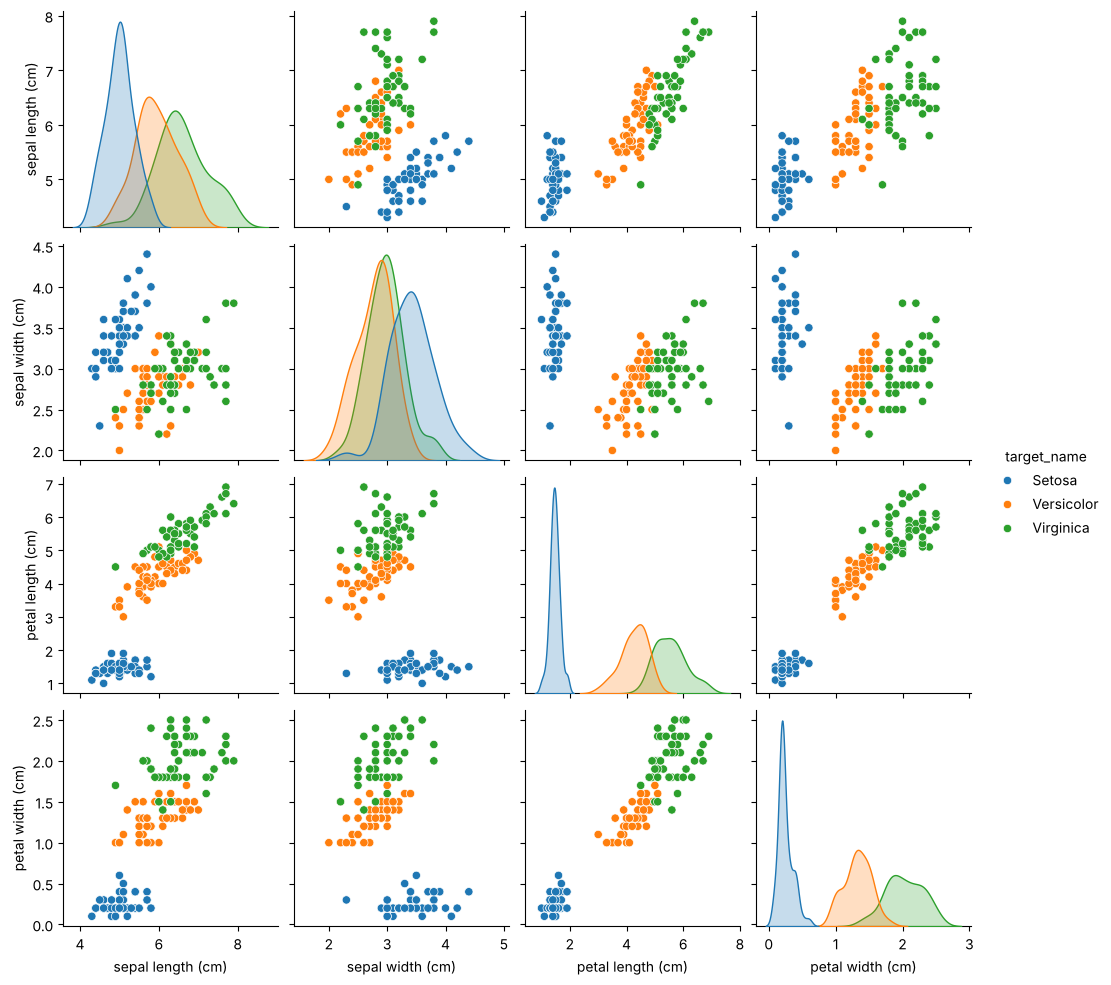

In [6]:
target_names = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
df_iris['target_name'] = df_iris['target'].map(target_names)
sns.pairplot(df_iris.drop(columns='target'), hue='target_name', diag_kind='kde')
plt.show()

### Decision boundaries (listed in the book's exercises)
To draw boundaries in 2D we train both strategies on only two features (petal length & width).

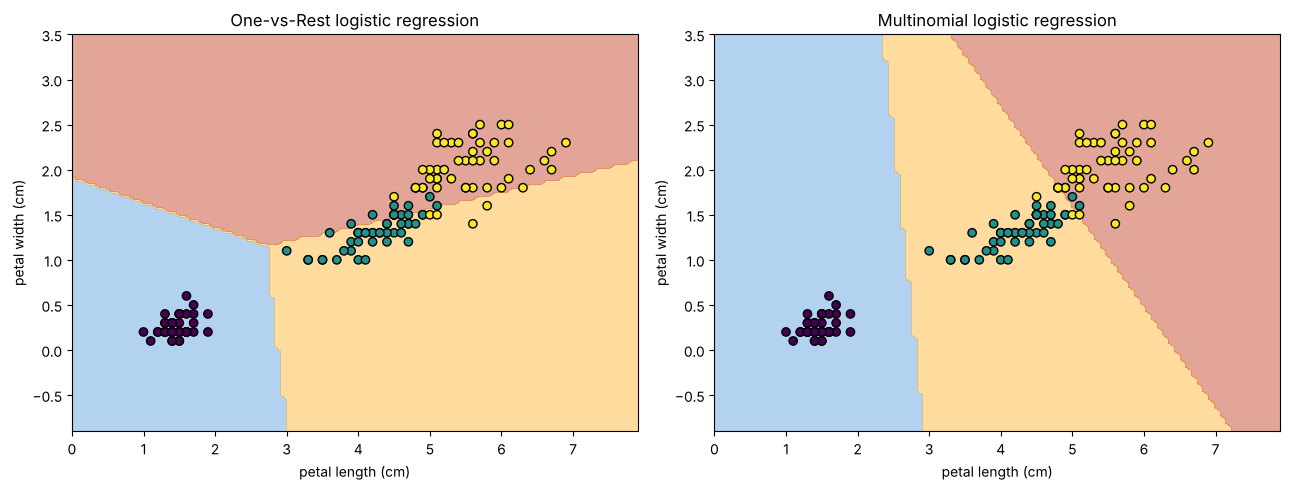

In [7]:
from sklearn.inspection import DecisionBoundaryDisplay

X2 = X[:, 2:4]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.3, random_state=2024)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, mdl) in zip(axes, [
        ("One-vs-Rest", OneVsRestClassifier(LogisticRegression(solver='liblinear'))),
        ("Multinomial", LogisticRegression(solver='lbfgs', max_iter=1000))]):
    mdl.fit(X2_train, y2_train)
    DecisionBoundaryDisplay.from_estimator(mdl, X2, response_method="predict", alpha=0.4, ax=ax,
                                           xlabel="petal length (cm)", ylabel="petal width (cm)")
    ax.scatter(X2[:, 0], X2[:, 1], c=y, edgecolor="k")
    ax.set_title(f"{name} logistic regression")
plt.tight_layout()
plt.show()

## 3. Regularisation in logistic regression

**Theory.** As in Chapter 5, a penalty on the size of the coefficients limits overfitting — particularly valuable with many features.

* **L2 (Ridge):** penalty proportional to the **square** of coefficients → shrinks them, rarely to exactly zero.
* **L1 (Lasso):** penalty proportional to the **absolute value** → drives some coefficients to exactly zero (feature selection).
* `C` is the **inverse** of the regularisation strength: **smaller `C` = stronger regularisation**.
* Solvers: `liblinear` supports L1 and L2 on small datasets; `saga` is a good choice for larger ones.
* **Scale the data first** — regularisation is sensitive to feature scale — and tune `C` (grid/random search).

In [8]:
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Ridge (L2)
ridge_model = LogisticRegression(penalty='l2', solver='liblinear', C=0.1)
ridge_model.fit(X_train, y_train)

# Lasso (L1)
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.1)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

print("Ridge (L2) accuracy:", round(accuracy_score(y_test, y_pred_ridge), 4))
display(styled_report(y_test, y_pred_ridge))
print("Lasso (L1) accuracy:", round(accuracy_score(y_test, y_pred_lasso), 4))
display(styled_report(y_test, y_pred_lasso))
print("Non-zero coefficients -> Ridge:", np.sum(ridge_model.coef_ != 0), "| Lasso:", np.sum(lasso_model.coef_ != 0))

Ridge (L2) accuracy: 0.9825


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logi

,precision,recall,f1-score,support
0,0.985,0.970,0.977,67
1,0.981,0.990,0.986,104
accuracy,0.982,0.982,0.982,1
macro avg,0.983,0.980,0.982,171
weighted avg,0.982,0.982,0.982,171


Lasso (L1) accuracy: 0.9649


,precision,recall,f1-score,support
0,0.930,0.985,0.957,67
1,0.990,0.952,0.971,104
accuracy,0.965,0.965,0.965,1
macro avg,0.960,0.968,0.964,171
weighted avg,0.966,0.965,0.965,171


Non-zero coefficients -> Ridge: 30 | Lasso: 7


Both give quality performance; which is "better" depends on the metric: in the book Ridge is slightly better in accuracy and precision while Lasso is better in recall.

**Visualising regularisation: coefficients as a function of `C`.**

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logi

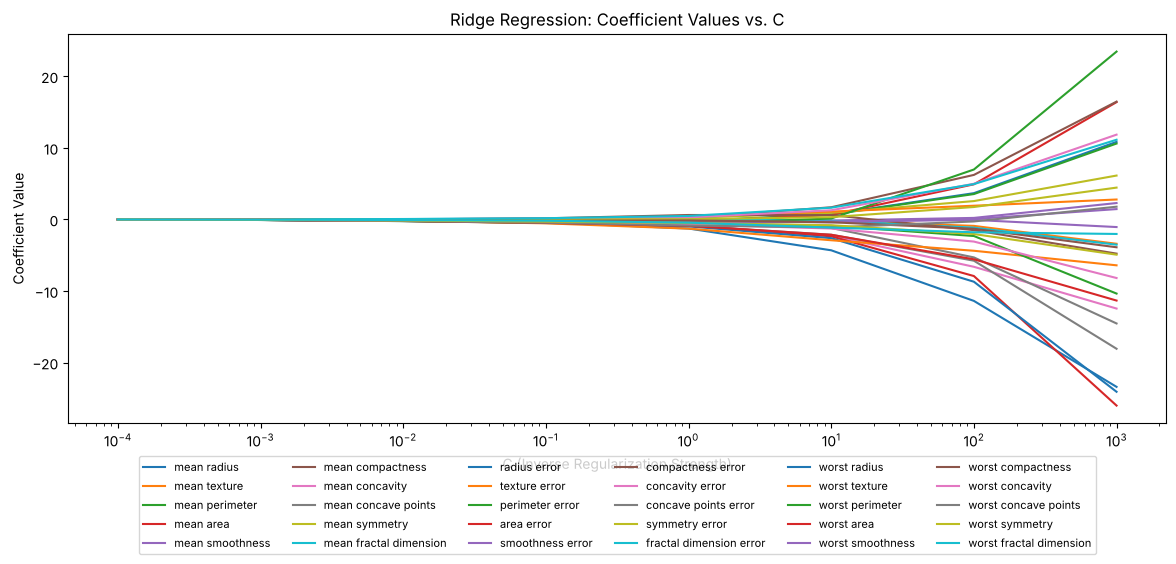

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

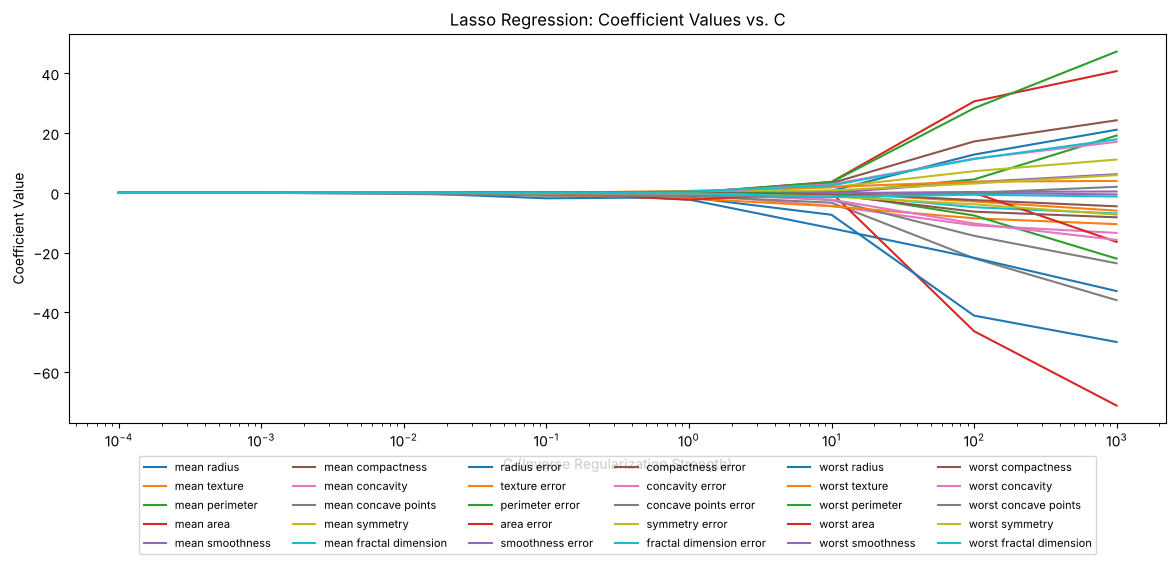

In [9]:
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])

def coef_path(penalty):
    out = []
    for C in C_values:
        m = LogisticRegression(penalty=penalty, solver='liblinear', C=C).fit(X_train, y_train)
        out.append(m.coef_[0])
    return out

for penalty, title in [('l2', 'Ridge'), ('l1', 'Lasso')]:
    coefs = coef_path(penalty)
    plt.figure(figsize=(12, 6))
    for i in range(X.shape[1]):
        plt.plot(C_values, [c[i] for c in coefs], label=feature_names[i])
    plt.xscale('log')
    plt.xlabel('C (Inverse Regularization Strength)')
    plt.ylabel('Coefficient Value')
    plt.title(f'{title} Regression: Coefficient Values vs. C')
    plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc='lower center', fontsize=8)
    plt.tight_layout()
    plt.show()

## 4. Multilabel classification concepts

**Theory.** In **multilabel** classification each instance may belong to **several classes simultaneously** (e.g. a photo tagged *beach* and *sunset*; a text with several topics). It differs from multiclass, where exactly one label is chosen.

Strategy used here: **one-vs-rest** — train an independent binary logistic regression for each label. `MultiOutputClassifier` is a shortcut that does the same. Other strategies: binary relevance and **classifier chains** (which model dependencies between labels).

`make_multilabel_classification` generates the data (`n_labels=2` is only the *average* number of labels per record, not a guarantee).

In [10]:
from sklearn.datasets import make_multilabel_classification

X, y = make_multilabel_classification(n_samples=1000, n_features=20, n_classes=5,
                                      n_labels=2, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Train one binary model per label (column of y)
models, y_pred_all = [], []
for i in range(y_train.shape[1]):
    m = LogisticRegression(solver='liblinear')
    m.fit(X_train, y_train[:, i])
    models.append(m)
    y_pred_all.append(m.predict(X_test))

y_pred = np.array(y_pred_all).T   # back to (n_samples, n_labels)

print("Subset accuracy (all labels exactly right):", round(accuracy_score(y_test, y_pred), 3))
rep = pd.DataFrame(classification_report(y_test, y_pred, zero_division=1, output_dict=True)).transpose()
display(rep.style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

Subset accuracy (all labels exactly right): 0.34


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562


In [11]:
# The shortcut mentioned in the book
from sklearn.multioutput import MultiOutputClassifier

moc = MultiOutputClassifier(LogisticRegression(solver='liblinear')).fit(X_train, y_train)
print("MultiOutputClassifier subset accuracy:", round(accuracy_score(y_test, moc.predict(X_test)), 3))

MultiOutputClassifier subset accuracy: 0.34


**Visualising label co-occurrence.** The left heatmap shows how often labels *i* and *j* appear together (diagonal = how often each label appears). The right heatmap normalises by the diagonal: cell (i, j) = share of samples with label *i* that also have label *j*. (The book's function has a missing comma in the `annot_kws` call; it is fixed here.)

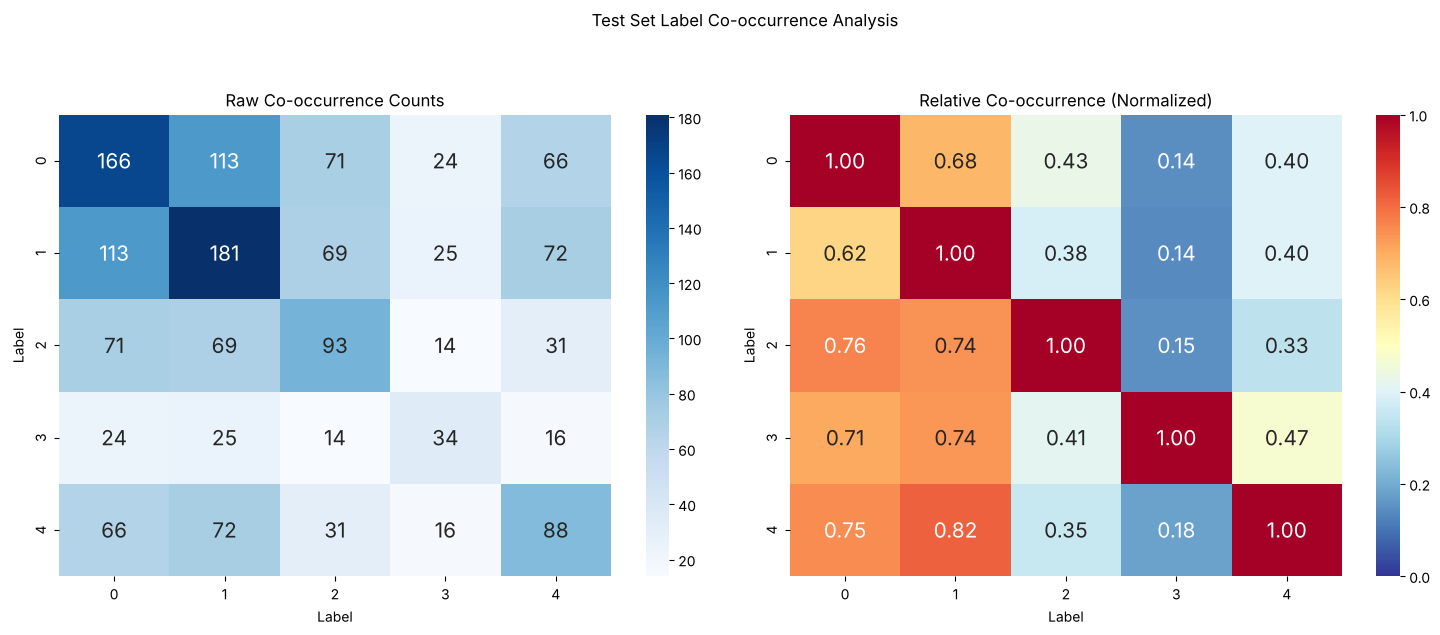


Label Statistics:
Total samples: 300

Label frequencies:
Label 0: 166 samples (55.3%)
Label 1: 181 samples (60.3%)
Label 2: 93 samples (31.0%)
Label 3: 34 samples (11.3%)
Label 4: 88 samples (29.3%)

Most common label combinations:
Combination [0 0 0 0 0]: 52 samples (17.3%)
Combination [0 1 0 0 0]: 34 samples (11.3%)
Combination [1 1 0 0 0]: 28 samples (9.3%)
Combination [1 1 1 0 0]: 25 samples (8.3%)
Combination [1 1 0 0 1]: 24 samples (8.0%)


In [12]:
def plot_label_cooccurrence(y, title="Label Co-occurrence Analysis"):
    cooccurrence = y.T @ y                          # raw counts
    diag = np.diag(cooccurrence)
    relative_cooccurrence = cooccurrence / diag[:, None]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Blues', ax=ax1, annot_kws={"fontsize": 15})
    ax1.set_title('Raw Co-occurrence Counts'); ax1.set_xlabel('Label'); ax1.set_ylabel('Label')

    sns.heatmap(relative_cooccurrence, annot=True, fmt='.2f', cmap='RdYlBu_r', ax=ax2,
                annot_kws={"fontsize": 15}, vmin=0, vmax=1)
    ax2.set_title('Relative Co-occurrence (Normalized)'); ax2.set_xlabel('Label'); ax2.set_ylabel('Label')
    plt.suptitle(title, y=1.05); plt.tight_layout()
    plt.show()

    print("\nLabel Statistics:")
    print(f"Total samples: {len(y)}")
    print("\nLabel frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        print(f"Label {i}: {count} samples ({count / len(y) * 100:.1f}%)")

    print("\nMost common label combinations:")
    combos, counts = np.unique(y, axis=0, return_counts=True)
    idx = np.argsort(-counts)
    for combo, count in zip(combos[idx][:5], counts[idx][:5]):
        print(f"Combination {combo}: {count} samples ({count / len(y) * 100:.1f}%)")

plot_label_cooccurrence(y_test, "Test Set Label Co-occurrence Analysis")

Reading the combination `[1 1 0 0 0]`: label 0 and label 1 present, labels 2–4 absent.

## 5. Model evaluation metrics

**Theory (recap).**

* **Accuracy** – share of correct predictions.
* **Precision** – of the predicted positives, how many are truly positive (few false positives).
* **Recall** – of the actual positives, how many were found (few false negatives).
* **F1-score** – harmonic mean of precision and recall; balanced measure.
* **ROC curve** – true-positive rate vs false-positive rate across all thresholds.
* **AUC** – area under the ROC curve; 1.0 = perfect, 0.5 = random guessing.

Choose according to cost: if false positives are costly, favour precision; if missing positives is costly (e.g. disease), favour recall.

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_curve, auc

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.3, random_state=2024)

model = LogisticRegression(solver='liblinear')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

print(f"Accuracy {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall {recall:.2f}")
print(f"F1 Score {f1:.2f}")
print(f"ROC AUC {roc_auc:.2f}")
print("Classification Report")
print(classification_report(y_test, y_pred))

Accuracy 0.94
Precision 0.94
Recall 0.95
F1 Score 0.95
ROC AUC 0.99
Classification Report
              precision    recall  f1-score   support

           0       0.92      0.91      0.92        67
           1       0.94      0.95      0.95       104

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



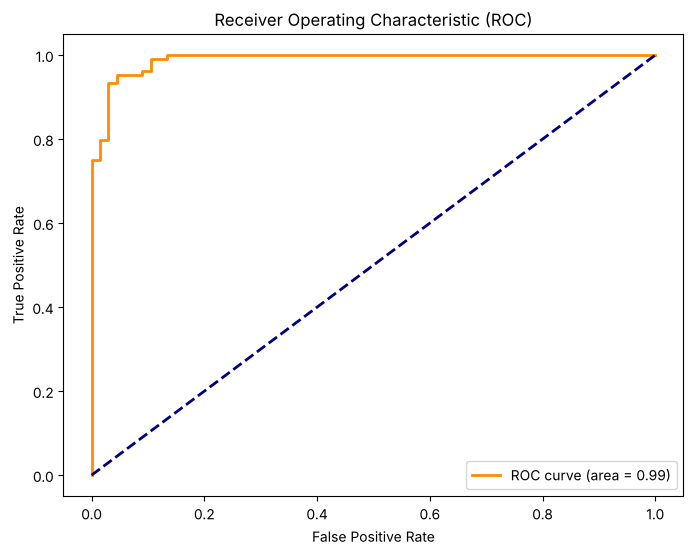

In [14]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

## 6. Practical exercises with advanced logistic regression

### Exercise 1 — Regularised logistic regression (Breast Cancer), Lasso and Ridge

In [15]:
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.3, random_state=2024)
sc = StandardScaler().fit(X_train)
Xs_train, Xs_test = sc.transform(X_train), sc.transform(X_test)

for pen in ['l1', 'l2']:
    m = LogisticRegression(penalty=pen, solver='liblinear', C=0.5).fit(Xs_train, y_train)
    print(f"{pen.upper()}  accuracy = {accuracy_score(y_test, m.predict(Xs_test)):.3f}  "
          f"non-zero coefs = {np.sum(m.coef_ != 0)}")

L1  accuracy = 0.971  non-zero coefs = 11
L2  accuracy = 0.982  non-zero coefs = 30


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

### Exercise 2 — Evaluate multiclass logistic regression (Iris, multinomial)

In [16]:
iris = load_iris()
Xi_train, Xi_test, yi_train, yi_test = train_test_split(iris.data, iris.target, test_size=0.3, random_state=2024)
mn = LogisticRegression(solver='lbfgs', max_iter=1000).fit(Xi_train, yi_train)
print("accuracy:", round(accuracy_score(yi_test, mn.predict(Xi_test)), 3))
print(classification_report(yi_test, mn.predict(Xi_test), target_names=iris.target_names))

accuracy: 0.933
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.85      0.92      0.88        12
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.92      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



### Exercise 3 — Visualise decision boundaries (synthetic binary dataset)

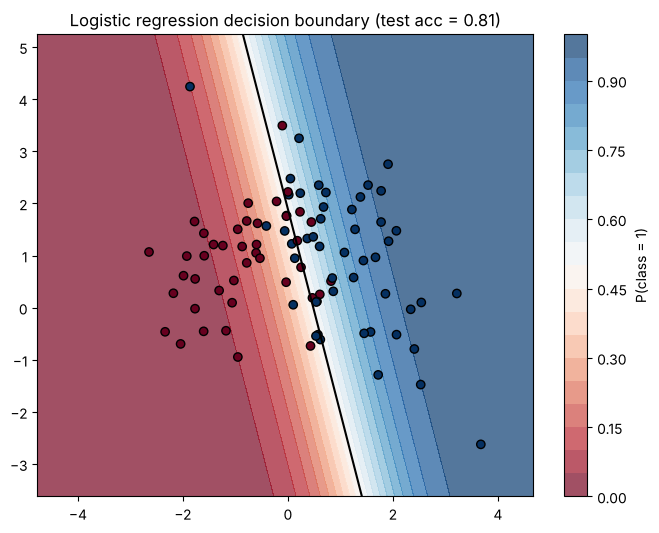

In [17]:
from sklearn.datasets import make_classification

Xs, ys = make_classification(n_samples=300, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, random_state=2024)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=2024)
lr = LogisticRegression().fit(Xs_tr, ys_tr)

# Mesh grid and predicted probabilities
xx, yy = np.meshgrid(np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 300),
                     np.linspace(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1, 300))
probs = lr.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx, yy, probs, levels=20, cmap="RdBu", alpha=0.7)
plt.colorbar(cs, label="P(class = 1)")
plt.contour(xx, yy, probs, levels=[0.5], colors="k")   # decision boundary
plt.scatter(Xs_te[:, 0], Xs_te[:, 1], c=ys_te, edgecolor="k", cmap="RdBu")
plt.title(f"Logistic regression decision boundary (test acc = {lr.score(Xs_te, ys_te):.2f})")
plt.show()

---
### Chapter 6 key takeaways
1. Logistic regression = linear model + sigmoid → probabilities; threshold turns them into classes.
2. Multiclass: **OvR** (one model per class) vs **multinomial/SoftMax** (joint model). Multilabel: one binary classifier per label.
3. `C` is the *inverse* regularisation strength; L1 gives sparsity, L2 gives shrinkage; scale the features first.
4. Evaluate with precision, recall, F1 and ROC-AUC — pick the metric according to the cost of errors.